# MATSim vs. Microcensus (MZMV 2015): Travel Behavior Comparison
**Project focus: Validation of Synthetic Population and Simulated Travel Demand**

This notebook performs a comprehensive comparative analysis between the synthetically generated travel demand (MATSim) and the observed travel diaries from the Swiss Microcensus on Mobility and Transport 2015 (MZMV 2015). 

> **Note on Data Dictionary:** The mapping of Microcensus categorical variables (e.g., transport modes `f51300`, purpose, employment) heavily relies on the official data dictionary: `2017-05-08-Datenbankstruktur_MZMV2015_mit_Geodaten.xlsx`.

---
### TODO: Nødvendige tilpasninger før du kjører koden
* **Stier (Paths):** Sjekk at stiene til `MATSIM_DIR` og `MZ_DIR` stemmer overens med mappestrukturen din.
* **Kolonnenavn for distanse (MZ):** Sjekk om filen `wege.csv` bruker `f51100`, `wdist`, eller `wdist_m` for reiselengde, og oppdater variabelen `MZ_DIST_COL` under.
* **Trafikktellinger (GEH):** Du må bytte ut dummy-dataene i del 6 med de faktiske telledataene fra MATSim-simuleringen og de fysiske tellepunktene i nettverket ditt.



In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path
import shapely.geometry 

# Plotting configuration for high-quality academic outputs
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2, palette="colorblind")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 150



## 1. Configuration & Data Loading
Setting up the environment and defining parameters. We map the main transport modes from the MZMV2015 (`f51300`) to MATSim terminology to ensure a 1:1 comparison.


In [2]:
# ==========================================
# CONFIGURATION
# ==========================================
MATSIM_DIR = Path('simulation_filter')
MZ_DIR = Path('microcensus_filter')

FOCUS_MODE = 'bike' # The specific mode evaluated in depth for this project

# Distance bins (in meters)
BINS = [0, 2000, 5000, 10000, 20000, 50000, np.inf]
BIN_LABELS = ['0-2 km', '2-5 km', '5-10 km', '10-20 km', '20-50 km', '50+ km']

# Socio-demographics to analyze (Ensuring at least 2 as required)
SOCIO_DEMOS = ['age_group', 'sex_group', 'employment_group']

# Mapping f51300 (Hauptverkehrsmittel) to MATSim modes 
# Reference: 2017-05-08-Datenbankstruktur_MZMV2015_mit_Geodaten.xlsx
MZ_MODE_MAP = {
    1: 'other',       # Flugzeug
    2: 'pt',       # bahn
    3: 'pt',      # postauto
    4: 'other',        # schiff
    5: 'pt',        # tram
    6: 'pt',        # bus
    7: 'pt',         # sonstiger oec
    8: 'other',         # reisecar
    9: 'car',         # auto
    10: 'other',     # lastwagen
    11: 'car_passenger',     # Taxi
    12: 'car',      # motorrad
    13: 'moped',      # mofa
    14: 'bike',      # velo
    15: 'walk',      # fuss
    16: 'other',      # ahrzeugähnliche Geräte
    17: 'other',      # anderes, weiss nicht, keine Antwort
    
}

# TODOk: Sjekk hva distansekolonnen for wege (turer) heter i ditt Microcensus-uttrekk.
MZ_DIST_COL = 'w_rdist' # Bytt til 'f51100' hvis wdist_m ikke finnes i wege.csv

### Loading and Merging Datasets
We merge the trip datasets with the person datasets to inherit sociodemographic attributes (age, sex, employment) and, crucially for the Microcensus, the expansion weights (`WP`).


In [3]:
def load_and_prepare_data():
    try:
        # Load MATSim Data
        ms_persons = pd.read_csv(MATSIM_DIR / 'simulation_persons.csv', keep_default_na=False)
        ms_trips = pd.read_csv(MATSIM_DIR / 'simulation_trips.csv', keep_default_na=False)
        
        # Load Microcensus Data
        mz_persons = pd.read_csv(MZ_DIR / 'microcensus_ne_weekday_persons.csv', keep_default_na=False)
        mz_trips = pd.read_csv(MZ_DIR / 'microcensus_ne_weekday_trips.csv', keep_default_na=False)
        
        # Merge Person demographics into Trips
        # MATSim uses 'person', MZ uses 'HHNR' (Target persons in households)
        ms_merged = ms_trips.merge(ms_persons[['person', 'carAvail', 'bikeAvail', "municipalityType", "ovgk"]], on='person', how='left')
        
        # In MZ, we need the person weights (WP) and household coordinates (hh_W_X_CH1903)
        mz_demo_cols = ['HHNR', 'alter', 'gesl', 'erwerb', 'hh_W_X_CH1903', 'hh_W_Y_CH1903', "AMSTAT", "f42100e", "f42100a", "hh_W_staedt_char_2012", "hh_W_OeV_KLASSE"]
        # TOD OK: Sjekk at disse demografiske kolonnene ('alter', 'gesl', 'erwerb') finnes i person-filen din. Endre navn hvis nødvendig.
        available_mz_cols = [c for c in mz_demo_cols if c in mz_persons.columns]
        
        mz_merged = mz_trips.merge(mz_persons[available_mz_cols], on='HHNR', how='left')
        
        # Apply Mode Mapping to MZ
        # TODO: Sjekk at wmittel finnes i mz_trips (wege.csv). Hvis ikke, bruk riktig kolonne for hovedtransportmiddel.
        if 'wmittel' in mz_merged.columns:
            mz_merged['mode'] = pd.to_numeric(mz_merged['wmittel'], errors='coerce').map(MZ_MODE_MAP).fillna('other')
        else:
            print("WARNING: 'wmittel' missing from MZ trips. Mode mapping bypassed.")
            mz_merged['mode'] = 'unknown'

        
            
        # Filter MATSim for age >= 6 (comparable universe)
        ms_merged = ms_merged[ms_merged['comparison_age_eligible'] == True]
        
        return ms_merged, mz_merged
    except FileNotFoundError as e:
        print(f"File not found. Please ensure the preprocessing scripts have been executed. Error: {e}")
        return pd.DataFrame(), pd.DataFrame()

ms_df, mz_df = load_and_prepare_data()
# Quick validation print
if not ms_df.empty and not mz_df.empty:
    print(f"Loaded MATSim Trips: {len(ms_df):,}")
    print(f"Loaded Microcensus Trips: {len(mz_df):,}")
    print(f"MATSim Columns: {ms_df.columns.tolist()}")
    print(f"Microcensus Columns: {mz_df.columns.tolist()}")



Loaded MATSim Trips: 48,252
Loaded Microcensus Trips: 6,441
MATSim Columns: ['person', 'trip_index', 'origin_activity_index', 'destination_activity_index', 'origin_type', 'destination_type', 'origin_x', 'origin_y', 'destination_x', 'destination_y', 'leg_count', 'modes', 'routing_modes', 'route_distance_m', 'has_boundary_proxy', 'age_group', 'sex_group', 'employment_group', 'comparison_age_eligible', 'sample_weight', 'carAvail', 'bikeAvail', 'municipalityType', 'ovgk']
Microcensus Columns: ['HHNR', 'WP', 'AUSNR', 'WEGNR', 'DMOD', 'f51100', 'f51400', 'f51100time', 'f51400time', 'pseudo', 'W_X', 'W_Y', 'W_X_CH1903', 'W_Y_CH1903', 'W_QAL', 'W_BFS', 'W_PLZ', 'W_Ort', 'W_Str', 'W_hnr', 'W_SPRACHE', 'W_REGION', 'W_KANTON', 'W_AGGLO2000', 'W_AGGLO_GROESSE2000', 'W_STRUKTUR_2000', 'W_STRUKTUR_AGG_2000', 'w_struktur_bfs9_2000', 'W_AGGLO2012', 'W_AGGLO_GROESSE2012', 'W_staedt_char_2012', 'W_stat_stadt_2012', 'W_ISO_Staedte_MIV', 'W_ISO_Staedte_OeV', 'W_OeV_KLASSE', 'W_DEGURBA', 'S_X', 'S_Y', 'S_X

/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_80805/2938622131.py:25: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mz_merged['mode'] = pd.to_numeric(mz_merged['wmittel'], errors='coerce').map(MZ_MODE_MAP).fillna('other')


In [4]:
def load_and_prepare_data():
    try:
        # Load MATSim Data
        ms_persons = pd.read_csv(MATSIM_DIR / 'simulation_persons.csv', keep_default_na=False)
        ms_trips = pd.read_csv(MATSIM_DIR / 'simulation_trips.csv', keep_default_na=False)
        
        # Load Microcensus Data
        mz_persons = pd.read_csv(MZ_DIR / 'microcensus_ne_weekday_persons.csv', keep_default_na=False)
        mz_trips = pd.read_csv(MZ_DIR / 'microcensus_ne_weekday_trips.csv', keep_default_na=False)
        
        # Merge Person demographics into Trips
        ms_merged = ms_trips.merge(ms_persons[['person', 'carAvail', 'bikeAvail', "municipalityType", "ovgk"]], on='person', how='left')
        
        mz_demo_cols = ['HHNR', 'alter', 'gesl', 'erwerb', 'hh_W_X_CH1903', 'hh_W_Y_CH1903', "AMSTAT", "f42100e", "f42100a", "hh_W_staedt_char_2012", "hh_W_OeV_KLASSE"]
        available_mz_cols = [c for c in mz_demo_cols if c in mz_persons.columns]
        mz_merged = mz_trips.merge(mz_persons[available_mz_cols], on='HHNR', how='left')
        
        # --- MZ Mode Mapping & Filtering ---
        if 'wmittel' in mz_merged.columns:
            mz_merged['mode'] = pd.to_numeric(mz_merged['wmittel'], errors='coerce').map(MZ_MODE_MAP).fillna('other')
        else:
            print("WARNING: 'wmittel' missing from MZ trips. Mode mapping bypassed.")
            mz_merged['mode'] = 'unknown'

        target_modes = {'pt', 'car', 'bike', 'walk'}
        
        initial_mz_count = len(mz_merged)
        mz_merged = mz_merged[mz_merged['mode'].isin(target_modes)]
        mz_rows_lost = initial_mz_count - len(mz_merged)
        print(f"Microcensus: Kept {len(mz_merged):,} rows across allowed modes ({', '.join(target_modes)}). Removed {mz_rows_lost:,} rows ({mz_rows_lost / initial_mz_count:.2%}).")

        # --- MATSim Mode Mapping & Filtering ---
        ms_mode_remap = {
            'car_passenger': 'car',
            'walk_loop': 'walk',
            'remote_walk': 'walk'
        }
        if 'routing_modes' in ms_merged.columns:
            ms_merged['routing_modes'] = ms_merged['routing_modes'].replace(ms_mode_remap)
            
            initial_ms_count = len(ms_merged)
            ms_merged = ms_merged[ms_merged['routing_modes'].isin(target_modes)]
            ms_rows_lost = initial_ms_count - len(ms_merged)
            print(f"MATSim: Kept {len(ms_merged):,} rows across allowed modes ({', '.join(target_modes)}). Removed {ms_rows_lost:,} rows ({ms_rows_lost / initial_ms_count:.2%}).")
        else:
            print("WARNING: 'mode' missing from MATSim trips. Filtering bypassed.")

        # Filter MATSim for age >= 6 (comparable universe)
        ms_merged = ms_merged[ms_merged['comparison_age_eligible'] == True]
        
        return ms_merged, mz_merged
    except FileNotFoundError as e:
        print(f"File not found. Please ensure the preprocessing scripts have been executed. Error: {e}")
        return pd.DataFrame(), pd.DataFrame()


ms_df, mz_df = load_and_prepare_data()
# Quick validation print
if not ms_df.empty and not mz_df.empty:
    print(f"Loaded MATSim Trips: {len(ms_df):,}")
    print(f"Loaded Microcensus Trips: {len(mz_df):,}")
    print(f"MATSim Columns: {ms_df.columns.tolist()}")
    print(f"Microcensus Columns: {mz_df.columns.tolist()}")



Microcensus: Kept 6,370 rows across allowed modes (bike, car, walk, pt). Removed 71 rows (1.10%).
MATSim: Kept 48,095 rows across allowed modes (bike, car, walk, pt). Removed 157 rows (0.33%).
Loaded MATSim Trips: 48,095
Loaded Microcensus Trips: 6,370
MATSim Columns: ['person', 'trip_index', 'origin_activity_index', 'destination_activity_index', 'origin_type', 'destination_type', 'origin_x', 'origin_y', 'destination_x', 'destination_y', 'leg_count', 'modes', 'routing_modes', 'route_distance_m', 'has_boundary_proxy', 'age_group', 'sex_group', 'employment_group', 'comparison_age_eligible', 'sample_weight', 'carAvail', 'bikeAvail', 'municipalityType', 'ovgk']
Microcensus Columns: ['HHNR', 'WP', 'AUSNR', 'WEGNR', 'DMOD', 'f51100', 'f51400', 'f51100time', 'f51400time', 'pseudo', 'W_X', 'W_Y', 'W_X_CH1903', 'W_Y_CH1903', 'W_QAL', 'W_BFS', 'W_PLZ', 'W_Ort', 'W_Str', 'W_hnr', 'W_SPRACHE', 'W_REGION', 'W_KANTON', 'W_AGGLO2000', 'W_AGGLO_GROESSE2000', 'W_STRUKTUR_2000', 'W_STRUKTUR_AGG_2000', '

/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_80805/3464162539.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mz_merged['mode'] = pd.to_numeric(mz_merged['wmittel'], errors='coerce').map(MZ_MODE_MAP).fillna('other')


## 2. Aggregated Mode-Share Comparison
This section compares the total modal split. The MATSim data represents the synthetic population directly, while the Microcensus data is weighted using the `WP` person weights to ensure representativeness at the cantonal level.


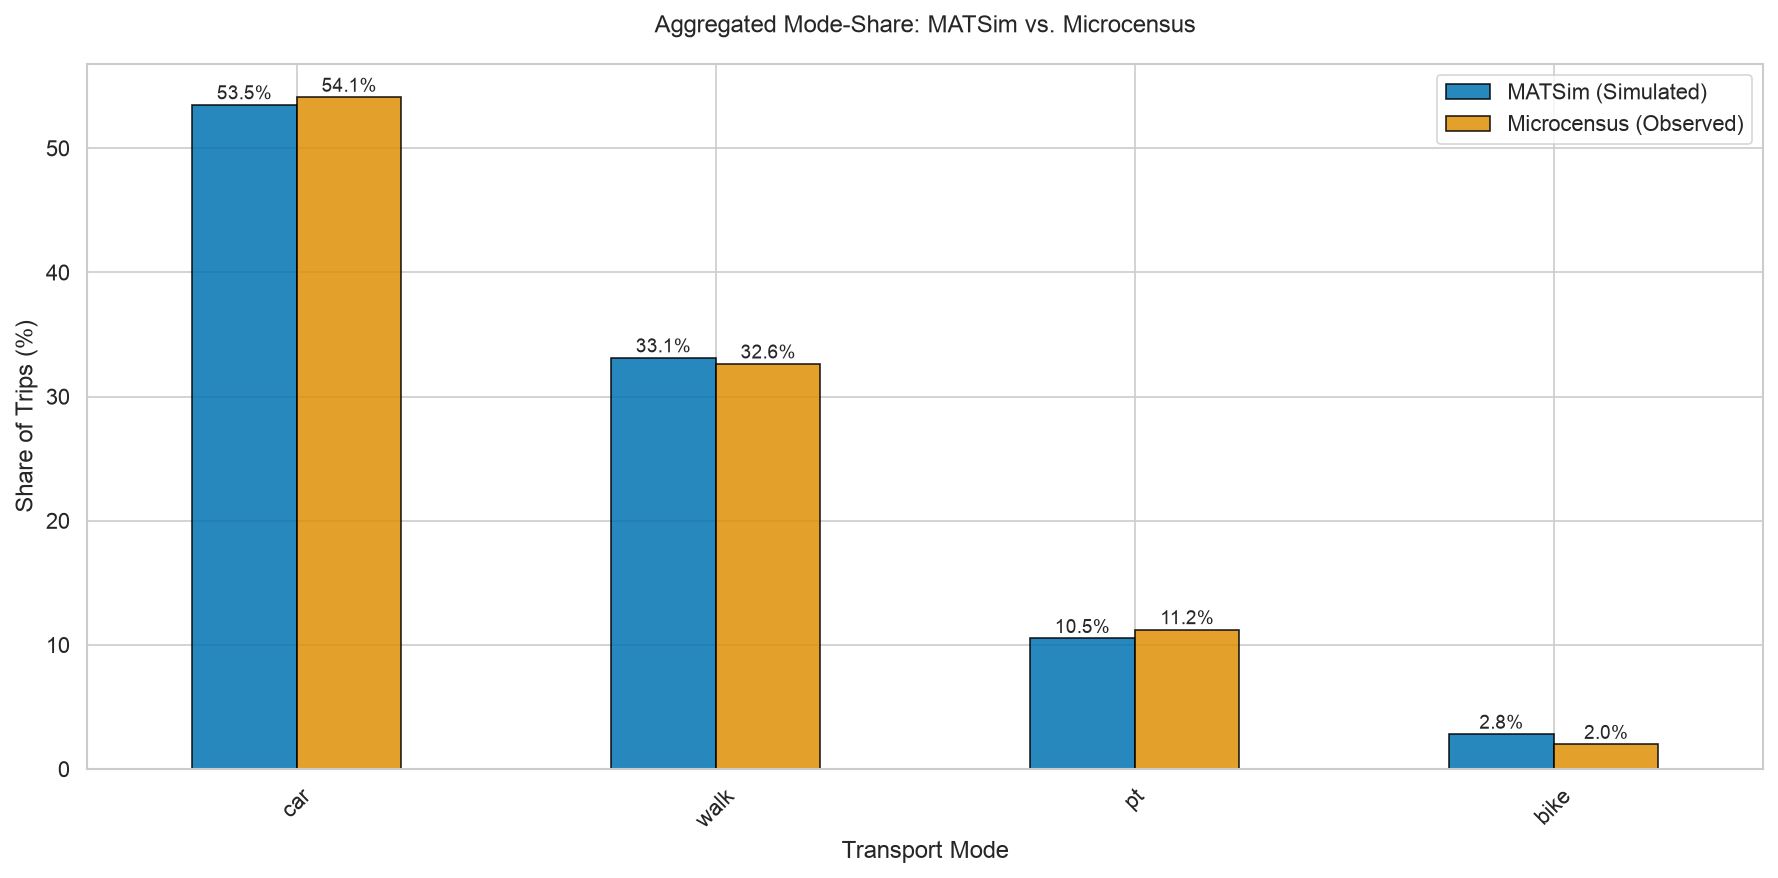

In [5]:
def check_aggregated_modeshare(ms, mz):
    if ms.empty or mz.empty: return
    
    # MATSim: Unweighted counts (or weight=1)
    ms_share = ms['routing_modes'].value_counts(normalize=True) * 100
    ms_share.name = 'MATSim (Simulated)'
    
    # Microcensus: Weighted by WP
    mz_weighted_counts = mz.groupby('mode')['WP'].sum()
    mz_share = (mz_weighted_counts / mz_weighted_counts.sum()) * 100
    mz_share.name = 'Microcensus (Observed)'
    
    # Align and plot
    df_share = pd.concat([ms_share, mz_share], axis=1).fillna(0)
    
    # Filter out near-zero categories for a cleaner plot
    df_share = df_share[(df_share > 0.5).any(axis=1)]
    
    ax = df_share.plot(kind='bar', edgecolor='black', alpha=0.85)
    plt.title('Aggregated Mode-Share: MATSim vs. Microcensus', pad=15)
    plt.ylabel('Share of Trips (%)')
    plt.xlabel('Transport Mode')
    plt.xticks(rotation=45)
    
    # Annotate bars
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)
        
    plt.legend()
    plt.tight_layout()
    plt.show()

check_aggregated_modeshare(ms_df, mz_df)



## 3. Mode-Share by Distance Bins
Travel behavior is highly dependent on trip distance. We aggregate trips into discrete spatial bins to verify whether the simulation captures the correct distance-decay behavior per mode (e.g., walking dominates short trips, cars/PT dominate long trips).


In [6]:
    mz['dist_bin'] = pd.cut(pd.to_numeric(mz[MZ_DIST_COL] * 1000, errors='coerce'), bins=BINS, labels=BIN_LABELS)


NameError: name 'mz' is not defined